# Analyzing the 6 versus 7 day work week using Chick-Fil-A as a case study

Imports and Settings

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import requests 
from io import StringIO
import numpy as np
from scipy import stats, optimize
import matplotlib.ticker as mtick

In [2]:
focusrestaurant = "Chick-Fil-A"

Getting the Data

Sources: https://finance.yahoo.com/small-business/articles/qsr-50-2026-top-50-121001353.html?guccounter=1

In [3]:
QSR_2025 = pd.DataFrame([
    # chain, category, US sales ($M), average sales per unit ($K), total units, QSR estimate?
    ("McDonald's", "Burger", 55061, 4088, 13706, False),
    ("Starbucks", "Snack", 30250, 1800, 16860, True),
    ("Chick-fil-A", "Chicken", 23918, 7700, 3287, True),
    ("Taco Bell", "Global", 17247, 2216, 7784, False),
    ("Dunkin'", "Snack", 13106, 1400, 9999, False),
    ("Wendy's", "Burger", 11898, 2001, 5969, False),
    ("Chipotle", "Global", 11679, 3104, 3938, False),
    ("Burger King", "Burger", 11074, 1660, 6649, False),
    ("Domino's", "Pizza", 9953, 1385, 7186, False),
    ("Subway", "Sandwich", 9200, 490, 18773, True),
    ("Panda Express", "Global", 6408, 2646, 2607, False),
    ("Panera", "Sandwich", 5894, 2611, 2214, True),
    ("Popeyes", "Chicken", 5698, 1800, 3196, False),
    ("Raising Cane's", "Chicken", 5487, 6580, 913, False),
    ("Wingstop", "Chicken", 5343, 2000, 2586, False),
    ("Sonic Drive-In", "Burger", 5242, 1500, 3412, False),
    ("Pizza Hut", "Pizza", 5094, 808, 6307, False),
    ("Dairy Queen", "Burger", 5013, 1218, 4115, False),
    ("KFC", "Chicken", 4682, 1329, 3523, False),
    ("Whataburger", "Burger", 4311, 3914, 1161, False),
    ("Arby's", "Sandwich", 4239, 1300, 3265, False),
    ("Jersey Mike's", "Sandwich", 4217, 1360, 3227, False),
    ("Jack in the Box", "Burger", 4209, 1970, 2131, False),
    ("Culver's", "Burger", 4200, 4040, 1041, False),
    ("Papa Johns", "Pizza", 3702, 1124, 3294, True),
    ("Little Caesars", "Pizza", 3700, 950, 4374, True),
    ("Zaxbys", "Chicken", 2764, 2768, 1005, False),
    ("Jimmy John's", "Sandwich", 2737, 1000, 2777, False),
    ("In-N-Out", "Burger", 2600, 6032, 431, True),
    ("Five Guys", "Burger", 2313, 1531, 1511, False),
    ("Dutch Bros", "Snack", 2224, 2115, 1136, False),
    ("Hardee's", "Burger", 2027, 1344, 1492, False),
    ("Bojangles", "Chicken", 1948, 2156, 867, False),
    ("Shake Shack", "Burger", 1541, 4048, 420, True),
    ("Tropical Smoothie Cafe", "Snack", 1513, 978, 1659, False),
    ("Crumbl", "Snack", 1483, 1139, 1101, True),
    ("Carl's Jr.", "Burger", 1426, 1422, 992, False),
    ("QDOBA", "Global", 1268, 1700, 827, False),
    ("Firehouse Subs", "Sandwich", 1209, 960, 1276, False),
    ("7 Brew", "Snack", 1200, 2600, 602, False),
    ("CAVA", "Global", 1169, 2934, 439, False),
    ("El Pollo Loco", "Chicken", 1125, 2300, 503, False),
    ("Marco's Pizza", "Pizza", 1094, 832, 1184, False),
    ("Freddy's", "Burger", 1040, 1901, 580, False),
    ("McAlister's", "Sandwich", 1029, 1868, 572, False),
    ("Nothing Bundt Cakes", "Snack", 982, 1261, 779, True),
    ("Dave's Hot Chicken", "Chicken", 966, 2718, 358, True),
    ("Del Taco", "Global", 919, 1600, 576, False),
    ("Church's Chicken", "Chicken", 862, 1138, 770, False),
    ("Scooter's Coffee", "Snack", 859, 999, 906, False),
], columns=["chain", "category", "sales_musd", "auv_kusd", "units", "estimate"]).set_index("chain")
QSR_2025.head(5)

,category,sales_musd,auv_kusd,units,estimate
chain,,,,,
McDonald's,Burger,55061,4088,13706,False
Starbucks,Snack,30250,1800,16860,True
Chick-fil-A,Chicken,23918,7700,3287,True
Taco Bell,Global,17247,2216,7784,False
Dunkin',Snack,13106,1400,9999,False


Plotting the Average Yearly Sales per Restaurant for each Franchise

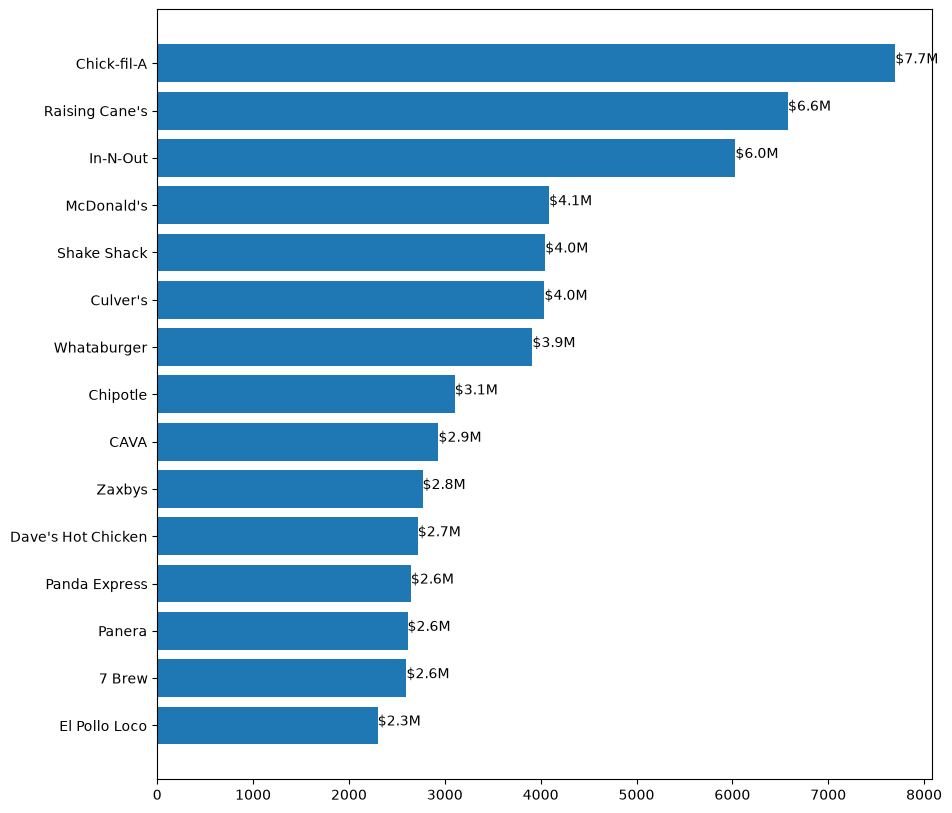

In [4]:
topx = 15
sortedQSR = QSR_2025.sort_values(by = "auv_kusd", ascending=False)
sortedQSR = sortedQSR.head(topx)
sortedQSR = sortedQSR.iloc[::-1]
fig, ax = plt.subplots(figsize = (10, 10))
bars = ax.barh(sortedQSR.index, sortedQSR["auv_kusd"])
for bar in bars:
    barwidth = bar.get_width()
    ax.text(barwidth, bar.get_y() + bar.get_height()/2, f"${barwidth/1000:.1f}M")
plt.show()

Doing hourly analysis to see hourly sales for each store to make sure that the difference is fully because of days and not hours

Focus Stores and hours open per week:

| Restaurant | Min | Max |
| :--- | :---: | :---: |
| Chick-Fil-A | 87 | 99 |
| Raising Cane's | 96 | 123 |
| In-N-Out | 102 | 103 |
| McDonald's | 126 | 168 |
| Chipotle | 74 | 88 |
| Culver's | 77 | 91 |

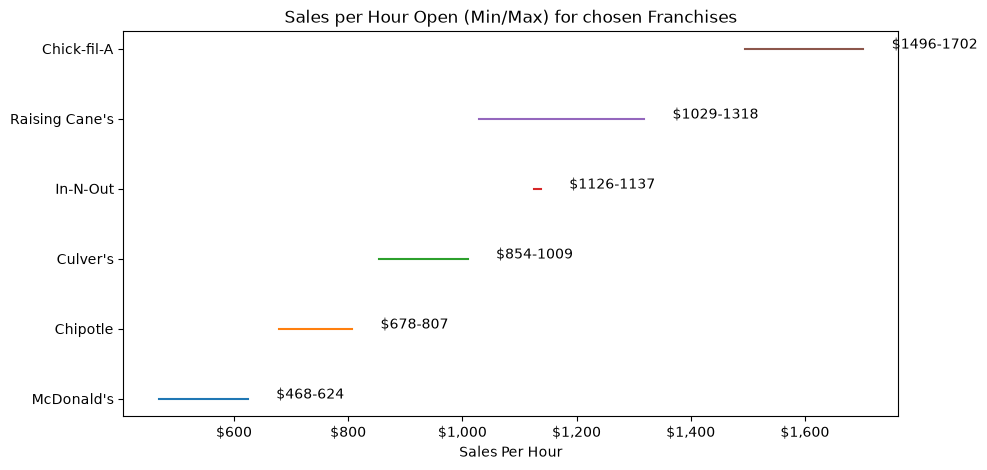

In [5]:
hours = pd.DataFrame({
    "low": {"Chick-fil-A": 87, "Raising Cane's": 96, "In-N-Out": 102, "McDonald's": 126, "Chipotle": 74, "Culver's": 77},
    "high": {"Chick-fil-A": 99, "Raising Cane's": 123, "In-N-Out": 103, "McDonald's": 168, "Chipotle": 88, "Culver's": 91},
})
salesperhour = pd.DataFrame({
    "high": QSR_2025.loc[hours.index, "auv_kusd"] * 1000 / (hours["low"] * 52),
    "low": QSR_2025.loc[hours.index, "auv_kusd"] * 1000 / (hours["high"] * 52),
})
salesperhour["mean"] = (salesperhour["low"] + salesperhour["high"]) / 2
salesperhour = salesperhour.sort_values("mean")

fig, ax = plt.subplots(figsize = (10, 5))
for index, (name, sales) in enumerate(salesperhour.iterrows()):
    ax.plot([sales["low"], sales["high"]], [index, index])
    ax.text(sales["high"] + 50, index, f"${sales["low"]:.0f}-{sales["high"]:.0f}")
ax.set_yticks(range(len(salesperhour)), labels=salesperhour.index)
ax.set_xlabel("Sales Per Hour")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Sales per Hour Open (Min/Max) for chosen Franchises")
plt.show()

Exploring data from multiple years

https://fred.stlouisfed.org/graph/fredgraph.csv 

In [6]:
focuslocations = ["Chick-fil-A", "McDonald's", "Chipotle", "Culver's", "In-N-Out", "Raising Cane's"]

(2025, np.float64(7700.0))
(2025, np.float64(4088.0))
(2025, np.float64(3104.0))
(2025, np.float64(4040.0))
(2025, np.float64(6032.0))
(2025, np.float64(6580.0))


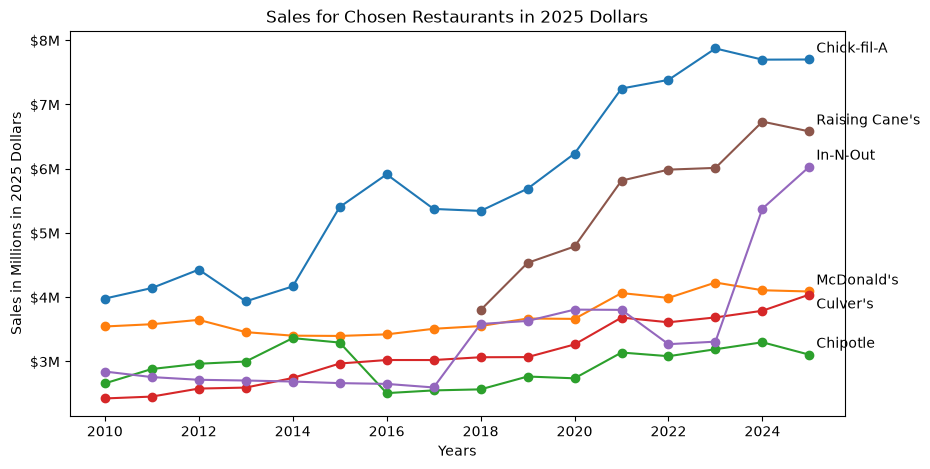

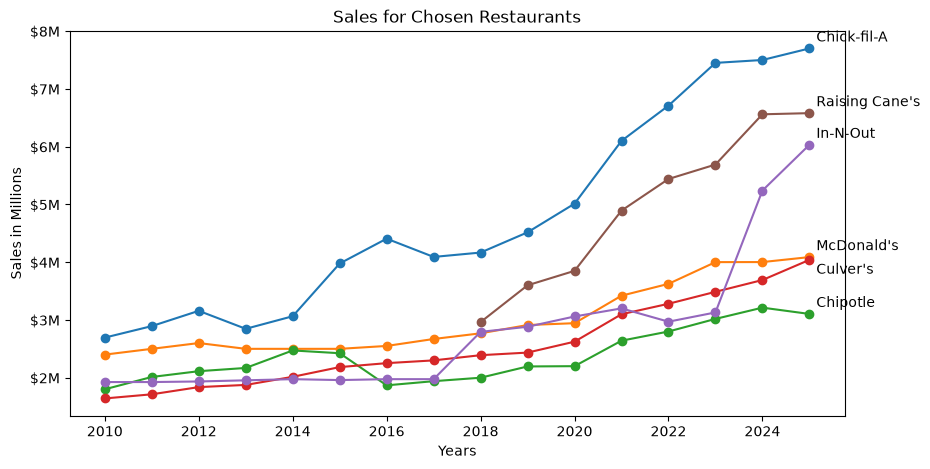

In [7]:
csvdatasource = "multiyeardata.csv"
yeardata = pd.read_csv(csvdatasource)
historicdata = yeardata.set_index("year")[focuslocations].sort_index()
cpi = pd.read_csv(StringIO(requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL", timeout=60).text),
                  parse_dates=["observation_date"])
cpi = cpi.groupby(cpi["observation_date"].dt.year)["CPIAUCSL"].mean()
deflatefactor = cpi.loc[2025] / cpi.loc[historicdata.index]
scaledsalesdata = historicdata.mul(deflatefactor.values, axis = 0)
fig, ax = plt.subplots(figsize = (10, 5))
for name in scaledsalesdata.columns:
    ax.plot(scaledsalesdata.index, scaledsalesdata[name] / 1000, marker = "o")
    print((scaledsalesdata.index[-1], scaledsalesdata[name].iloc[-1]))
    if name == "Culver's":
        ax.annotate(name, (scaledsalesdata.index[-1], scaledsalesdata[name].iloc[-1] / 1000), xytext=(5, -10), textcoords = "offset points")
    else:
        ax.annotate(name, (scaledsalesdata.index[-1], scaledsalesdata[name].iloc[-1] / 1000), xytext=(5, 5), textcoords = "offset points")
ax.set_xlabel("Years")
ax.set_ylabel("Sales in Millions in 2025 Dollars")
ax.set_title("Sales for Chosen Restaurants in 2025 Dollars")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
plt.show()


# for name in focuslocations:
#     yeardata[name] = pd.to_numeric(yeardata[name], errors="coerce").fillna(0).astype("int64")
# yeardata.head(10)

fig, ax = plt.subplots(figsize = (10, 5))
for name in yeardata.columns:
    if name not in focuslocations:
        continue
    ax.plot(yeardata["year"], yeardata[name] / 1000, marker = "o")
    if name == "Culver's":
        ax.annotate(name, (yeardata["year"].iloc[-1], yeardata[name].iloc[-1] / 1000), xytext=(5, -10), textcoords = "offset points")
    else:
        ax.annotate(name, (yeardata["year"].iloc[-1], yeardata[name].iloc[-1] / 1000), xytext=(5, 5), textcoords = "offset points")
ax.set_xlabel("Years")
ax.set_ylabel("Sales in Millions")
ax.set_title("Sales for Chosen Restaurants")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
plt.show()

Testing to see if there is a strong correlation between sales per location and number of locations

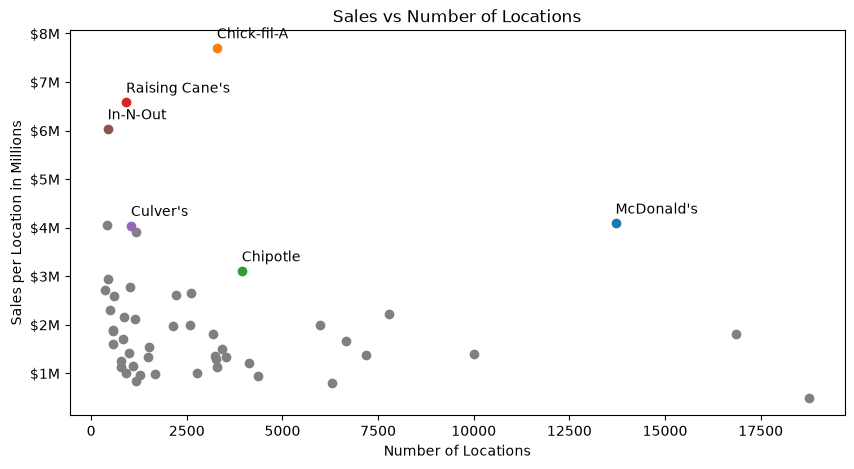

In [8]:

fig, ax = plt.subplots(figsize = (10, 5))
for name, sales in QSR_2025.iterrows():
    if name not in focuslocations:
        ax.scatter(sales["units"], sales["auv_kusd"] / 1000, color = "grey")
    else:
        ax.scatter(sales["units"], sales["auv_kusd"] / 1000)
    if name in focuslocations:
        ax.text(sales["units"], sales["auv_kusd"] / 1000 + .2, name)
ax.set_xlabel("Number of Locations")
ax.set_ylabel("Sales per Location in Millions")
ax.set_title("Sales vs Number of Locations")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
plt.show()

Compare Poland Sales and Economic Data before Sunday Ban. We also could compare Hungary which introduced a ban in 2015 but repealed it in 2016.

Sources:
https://ec.europa.eu/eurostat/databrowser/view/sts_trlb_q/default/table?lang=en

https://ec.europa.eu/eurostat/databrowser/view/sts_trtu_q/default/table?lang=en

In [20]:
europestatsurl = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data"
countries = ["PL", "HU", "CZ", "SK", "RO", "BG", "LT", "LV", "EE"]
controls = [c for c in countries if c != "PL"]
measures = {"VOL_SLS": "Sales volume", "HW": "Hours worked", "EMP": "Employment", "sales_per_hour": "Sales per hour worked"}
baseline = pd.period_range("2017Q1", "2017Q4", freq="Q")
phases = [("2018Q2", "2018Q4", "2018: 2 trading Sundays/month"), ("2019Q1", "2019Q4", "2019: 1 trading Sunday/month")]

def fetch_data(table, indicators):
    params = {"format": "JSON", "nace_r2": "G47", "s_adj": "SCA", "unit": "I21",
              "geo": countries, "indic_bt": indicators, "sinceTimePeriod": "2012-Q1"}

    response = requests.get(f"{europestatsurl}/{table}", params=params, timeout=120)
    response.raise_for_status()
    data = response.json()

    dims, sizes = data["id"], data["size"]
    codes = {d: {i: c for c, i in data["dimension"][d]["category"]["index"].items()} for d in dims}
    rows = []

    for flat_index, value in data["value"].items():
        index, row = int(flat_index), {}
        for dim, size in zip(reversed(dims), reversed(sizes)):
            row[dim] = codes[dim][index % size]
            index //= size
        row["value"] = value
        rows.append(row)

    return pd.DataFrame(rows)


sales = fetch_data("sts_trtu_q", "VOL_SLS")
labour = fetch_data("sts_trlb_q", ["HW", "EMP"])

retail = pd.concat([sales, labour])

retail = retail.pivot_table(index = ["geo", "time"], columns = "indic_bt", values = "value").reset_index()
retail["quarter"] = pd.PeriodIndex(retail["time"].str.replace("-", ""), freq = "Q")
retail["sales_per_hour"] = retail["VOL_SLS"]/retail["HW"]
retail.head(10)

indic_bt,geo,time,EMP,HW,VOL_SLS,quarter,sales_per_hour
0,BG,2012-Q1,100.4,107.1,56.1,2012Q1,0.523810
1,BG,2012-Q2,100.7,105.4,56.6,2012Q2,0.537002
2,BG,2012-Q3,99.4,103.8,57.1,2012Q3,0.550096
3,BG,2012-Q4,98.2,101.7,57.3,2012Q4,0.563422
4,BG,2013-Q1,99.6,104.3,55.2,2013Q1,0.529243
5,BG,2013-Q2,99.5,103.8,58.4,2013Q2,0.562620
6,BG,2013-Q3,98.9,102.7,60.0,2013Q3,0.584226
7,BG,2013-Q4,98.4,102.1,61.4,2013Q4,0.601371
8,BG,2014-Q1,99.4,100.9,62.9,2014Q1,0.623389
9,BG,2014-Q2,100.4,103.4,63.8,2014Q2,0.617021


In [24]:
def getchange(df, country, base, post):
    countrydata = df[df["geo"] == country]
    before = countrydata[countrydata["quarter"].isin(base)][list(measures)].mean()
    after = countrydata[countrydata["quarter"].isin(post)][list(measures)].mean()
    change = ((after/before) - 1) * 100
    return change

def getchangedifference(df, controls, base, post, country = "PL"):
    countrychange = getchange(df, country, base, post)
    otherchanges = []
    for country in controls:
        otherchanges.append(getchange(df, country, base, post))
    return countrychange - pd.concat(otherchanges, axis = 1).mean(axis = 1)

base = baseline
currentphase = phases[0]
post = pd.period_range(currentphase[0], currentphase[1], freq = "Q")
polanddifferences = getchangedifference(retail, controls, base, post)
print(polanddifferences)

currentphase = phases[1]
post = pd.period_range(currentphase[0], currentphase[1], freq = "Q")
polanddifferences = getchangedifference(retail, controls, base, post)
print(polanddifferences)

indic_bt
VOL_SLS           2.048544
HW                3.180023
EMP               0.077414
sales_per_hour   -1.277681
dtype: float64
indic_bt
VOL_SLS           2.427137
HW                4.917565
EMP              -1.890874
sales_per_hour   -2.648815
dtype: float64


indic_bt   VOL_SLS        HW       EMP  sales_per_hour
HU        2.696206  3.476130  3.325755       -0.940937
CZ       -0.476159  1.690221  0.730329       -2.238339
SK       -1.010686  0.758364  2.569717       -1.824003
RO        1.658068  2.100675  2.015358       -0.546844
BG       -0.944150 -2.592105 -2.298648        1.766959
indic_bt   VOL_SLS        HW       EMP  sales_per_hour
HU        4.545084  8.984110  9.119499       -4.641204
CZ       -0.091365 -0.259430  0.688207        0.112545
SK       -5.898835 -2.855100 -1.070155       -2.939559
RO        4.138520  4.059457  4.129643       -0.262448
BG        0.352558 -2.425535 -3.321963        2.856770


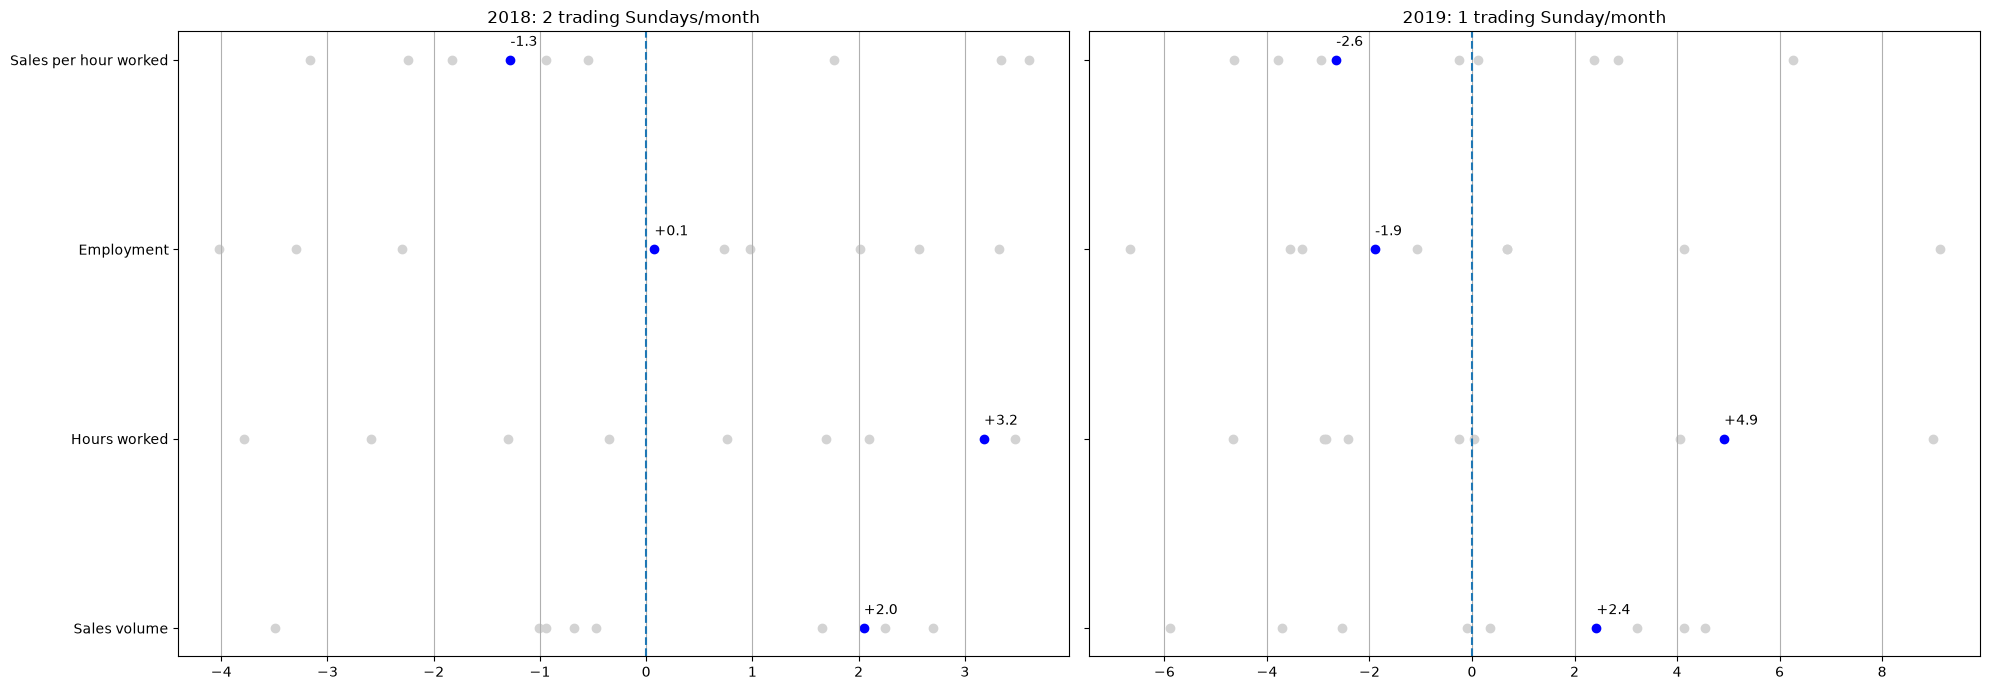

In [52]:
fig, ax = plt.subplots(1, 2, figsize = (20, 7), sharey = True)
for a, phase in zip(ax, phases):
    post = pd.period_range(phase[0], phase[1], freq = "Q")
    polanddifferences = getchangedifference(retail, controls, base, post)
    otherdifferences = pd.DataFrame({country:getchangedifference(retail, controls, base, post, country) for country in controls}).T
    print(otherdifferences.head(5))
    for i, measurment in enumerate(measures):
        a.scatter(otherdifferences[measurment], np.full(len(otherdifferences), i), color = "lightgray")
        a.scatter(polanddifferences[measurment], i, color = "blue")
        a.annotate(f"{polanddifferences[measurment]:+.1f}", (polanddifferences[measurment], i), xytext=(0, 10), textcoords="offset points")
    a.set_yticks(range(len(measures)), list(measures.values()))
    a.grid(axis = "x")
    a.axvline(x = 0, linestyle = "--")
    a.set_title(phase[2])
plt.tight_layout()
plt.show()